# Small-Catalog Recommendation Explorer


### Problem
A small study club has a catalog of about 60 books and wants to recommend books to members. Some members are brand new (no history) and some books are brand new (nobody read them yet). Offline clicks also do not prove people are happier, so I want to compare simple methods honestly.

### What I build
1. A fictional catalog of books and fake reading history with timestamps
2. Three recommenders: popularity, content similarity, and item-item collaborative filtering
3. A time based train/test split so the future never leaks into the past
4. Cold-start handling for new users and new books
5. Metrics: recall@5, catalog coverage and a simple diversity score
6. Explanations for each suggestion, and a "clear my history" check
7. Acceptance tests

### How to run
Just run all cells. No dataset download is needed because all data is made inside the notebook (fixed seed 42). Needs: pandas, numpy, scikit-learn, matplotlib.

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

## Step 1: Imports and settings

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.random.seed(42)
K = 5
print("ready, K =", K)

ready, K = 5


## Step 2: Make the fictional catalog
All books and authors are made up. Each genre has its own word pool, so books in the same genre look similar. The last 6 books are "new" (nobody has read them yet).

In [3]:
genres = {
    "Fantasy": ["dragon", "kingdom", "magic", "sword", "quest", "wizard", "elf", "prophecy"],
    "SciFi": ["starship", "robot", "galaxy", "future", "alien", "colony", "quantum", "cyber"],
    "Mystery": ["detective", "murder", "clue", "suspect", "alibi", "secret", "crime", "witness"],
    "Romance": ["love", "wedding", "heart", "letters", "summer", "promise", "kiss", "dance"],
    "History": ["empire", "war", "ancient", "revolution", "king", "battle", "trade", "treaty"],
    "SelfHelp": ["habit", "focus", "mindset", "goals", "routine", "growth", "energy", "money"],
    "Tech": ["python", "data", "network", "software", "algorithm", "cloud", "design", "code"],
}
common_words = ["story", "journey", "world", "life", "guide", "new", "tale"]
genre_list = list(genres.keys())

books = []
for i in range(60):
    g = genre_list[i % len(genre_list)]
    words = list(np.random.choice(genres[g], 4, replace=False)) + list(np.random.choice(common_words, 2, replace=False))
    title = words[0].title() + " " + words[1].title() + " " + str(i + 1)
    text = title + " " + g + " " + " ".join(words)
    books.append({"item_id": i, "title": title, "genre": g, "text": text, "is_new": i >= 54})

catalog = pd.DataFrame(books)
print(catalog.shape)
catalog.head()

(60, 5)


,item_id,title,genre,text,is_new
0,0,Kingdom Wizard 1,Fantasy,Kingdom Wizard 1 Fantasy kingdom wizard dragon...,False
1,1,Quantum Colony 2,SciFi,Quantum Colony 2 SciFi quantum colony starship...,False
2,2,Crime Clue 3,Mystery,Crime Clue 3 Mystery crime clue detective witn...,False
3,3,Love Wedding 4,Romance,Love Wedding 4 Romance love wedding summer let...,False
4,4,King Ancient 5,History,King Ancient 5 History king ancient battle tre...,False


## Step 3: Make fake reading history with timestamps
Each user likes 1 or 2 genres. Most reads come from liked genres and popular books get picked more often. 12 users are "late joiners" whose reads all happen near the end, so they will have no history in training (cold-start users).

In [4]:
n_users = 150
n_days = 180
old_items = catalog[~catalog["is_new"]]["item_id"].values

# some books are more popular than others
pop_weight = np.random.pareto(1.5, len(old_items)) + 0.2
pop_weight = pop_weight / pop_weight.sum()

rows = []
for u in range(n_users):
    fav = list(np.random.choice(genre_list, np.random.randint(1, 3), replace=False))
    late_joiner = u >= n_users - 12
    n_reads = np.random.randint(8, 21)
    for r in range(n_reads):
        if np.random.rand() < 0.8:
            pool = catalog[(catalog["genre"].isin(fav)) & (~catalog["is_new"])]["item_id"].values
        else:
            pool = old_items
        w = pop_weight[[list(old_items).index(p) for p in pool]]
        w = w / w.sum()
        item = int(np.random.choice(pool, p=w))
        if late_joiner:
            day = np.random.randint(int(n_days * 0.85), n_days)
        else:
            day = np.random.randint(0, n_days)
        rows.append({"user_id": u, "item_id": item, "day": day})

inter = pd.DataFrame(rows).drop_duplicates(["user_id", "item_id"]).reset_index(drop=True)
print("interactions:", len(inter), "| users:", inter["user_id"].nunique())
inter.head()

interactions: 926 | users: 150


,user_id,item_id,day
0,0,6,54
1,0,44,94
2,0,48,22
3,0,34,31
4,0,13,117


## Step 4: Time based split
Oldest 80% of reads are for training and the newest 20% are for testing. For every user, a "relevant" book is one they read in the test period that they had not read before.

In [5]:
cut_day = np.percentile(inter["day"], 80)
train = inter[inter["day"] < cut_day].copy()
test = inter[inter["day"] >= cut_day].copy()
print("cut day:", cut_day, "| train rows:", len(train), "| test rows:", len(test))

history = train.groupby("user_id")["item_id"].apply(set).to_dict()

relevant = {}
for u, grp in test.groupby("user_id"):
    seen = history.get(u, set())
    rel = set(grp["item_id"]) - seen
    if len(rel) > 0:
        relevant[u] = rel

all_users = sorted(inter["user_id"].unique())
cold_users = [u for u in all_users if u not in history]
print("users with relevant test items:", len(relevant))
print("cold-start users (no train history):", len(cold_users))

cut day: 156.0 | train rows: 736 | test rows: 190
users with relevant test items: 92
cold-start users (no train history): 4


## Step 5: The recommenders
All of them only use the `train` table. Books the user already read are never recommended (the task rule).
1. **Popularity** - most read books in train
2. **Content** - TF-IDF of title/genre/words, user profile is the average of the books they read
3. **Item-item CF** - books read by the same people look similar. For books with zero train reads (new books), it falls back to the content score so they can still show up

In [6]:
tfidf = TfidfVectorizer()
item_vecs = tfidf.fit_transform(catalog["text"])
content_sim = cosine_similarity(item_vecs)

n_items = len(catalog)
pop_counts = train["item_id"].value_counts()
pop_score = np.zeros(n_items)
for i, c in pop_counts.items():
    pop_score[i] = c

# user x item matrix from train only
mat = np.zeros((n_users, n_items))
for r in train.itertuples():
    mat[r.user_id, r.item_id] = 1
cf_sim = cosine_similarity(mat.T)
np.fill_diagonal(cf_sim, 0)
train_reads = mat.sum(axis=0)


def top_k(scores, seen, k=K):
    scores = scores.copy()
    for s in seen:
        scores[s] = -1e9
    order = np.argsort(-scores)
    return [int(x) for x in order[:k]]


def rec_popularity(seen):
    return top_k(pop_score, seen)


def rec_content(seen):
    if len(seen) == 0:
        return rec_popularity(seen)
    sc = content_sim[list(seen)].mean(axis=0)
    return top_k(sc, seen)


def rec_cf(seen):
    if len(seen) == 0:
        return rec_popularity(seen)
    cf_score = cf_sim[list(seen)].sum(axis=0)
    if cf_score.max() > 0:
        cf_score = cf_score / cf_score.max()
    content_score = content_sim[list(seen)].mean(axis=0)
    # new books have no reads so use content score for them
    final = cf_score.copy()
    for i in range(n_items):
        if train_reads[i] == 0:
            final[i] = 0.5 * content_score[i]
    return top_k(final, seen)


methods = {"Popularity": rec_popularity, "Content": rec_content, "ItemItem CF": rec_cf}
print("methods ready:", list(methods.keys()))

methods ready: ['Popularity', 'Content', 'ItemItem CF']


## Step 6: Evaluate on the same held-out set
- **recall@5** = hits / number of relevant books for the user
- **coverage** = share of the catalog that ever gets recommended
- **diversity** = distinct genres in the top 5 divided by 5 (higher means less repetitive)

In [7]:
genre_of = dict(zip(catalog["item_id"], catalog["genre"]))


def evaluate(fn, users):
    recalls = []
    shown = set()
    divs = []
    for u in users:
        seen = history.get(u, set())
        recs = fn(seen)
        shown.update(recs)
        rel = relevant[u]
        recalls.append(len(set(recs) & rel) / len(rel))
        divs.append(len(set(genre_of[x] for x in recs)) / len(recs))
    return np.mean(recalls), len(shown) / n_items, np.mean(divs)


warm_eval_users = [u for u in relevant if u in history]
cold_eval_users = [u for u in relevant if u not in history]
print("warm users evaluated:", len(warm_eval_users), "| cold users evaluated:", len(cold_eval_users))

results = []
for name, fn in methods.items():
    r, c, d = evaluate(fn, warm_eval_users)
    results.append({"method": name, "recall@5": round(r, 3), "coverage": round(c, 3), "diversity": round(d, 3)})
res_df = pd.DataFrame(results)
print(res_df)
res_df

warm users evaluated: 88 | cold users evaluated: 4
        method  recall@5  coverage  diversity
0   Popularity     0.330     0.183      0.907
1      Content     0.333     0.983      0.343
2  ItemItem CF     0.520     0.733      0.723


,method,recall@5,coverage,diversity
0,Popularity,0.330,0.183,0.907
1,Content,0.333,0.983,0.343
2,ItemItem CF,0.520,0.733,0.723


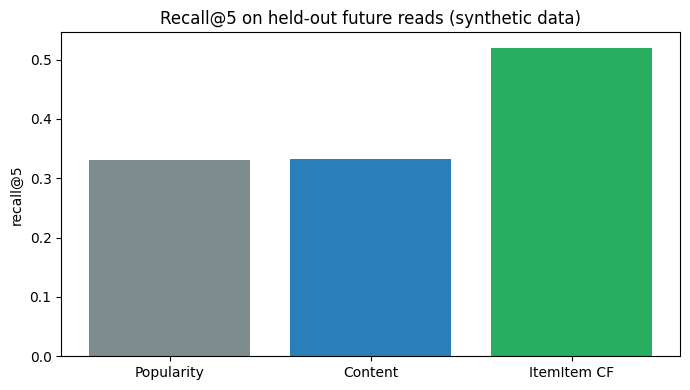

In [8]:
plt.figure(figsize=(7, 4))
plt.bar(res_df["method"], res_df["recall@5"], color=["#7f8c8d", "#2980b9", "#27ae60"])
plt.title("Recall@5 on held-out future reads (synthetic data)")
plt.ylabel("recall@5")
plt.tight_layout()
plt.savefig("recall_compare.png")
plt.show()

## Step 7: Cold start check
Cold users have no history, so every method falls back to popularity. This is on purpose and it is documented here, we do not fake a personalised list.

In [9]:
if len(cold_eval_users) > 0:
    r, c, d = evaluate(rec_popularity, cold_eval_users)
    print("cold users popularity fallback -> recall@5:", round(r, 3), "| diversity:", round(d, 3))

u = cold_users[0]
print("example cold user", u, "gets:", [catalog.loc[i, "title"] for i in rec_cf(set())])

new_ids = list(catalog[catalog["is_new"]]["item_id"])
cf_shown_new = 0
for u in warm_eval_users:
    recs = rec_cf(history.get(u, set()))
    cf_shown_new += len(set(recs) & set(new_ids))
print("new books shown by CF fallback (across all warm users):", cf_shown_new)

# a separate "new arrivals" shelf using content only, so new books still get a chance
d_user = warm_eval_users[0]
sc = content_sim[list(history[d_user])].mean(axis=0)
new_sc = [(sc[i], i) for i in new_ids]
new_sc.sort(reverse=True)
print("new arrivals shelf for user", d_user, ":", [catalog.loc[i, "title"] for s_, i in new_sc[:3]])

cold users popularity fallback -> recall@5: 0.458 | diversity: 1.0
example cold user 140 gets: ['Wizard Kingdom 15', 'Robot Galaxy 51', 'Routine Money 20', 'Crime Clue 3', 'Algorithm Network 7']
new books shown by CF fallback (across all warm users): 0
new arrivals shelf for user 5 : ['Summer Letters 60', 'Dragon Sword 57', 'Quantum Cyber 58']


## Step 8: Explanations and clearing history
For each suggestion I show the book the user read that is most similar to it, plus the shared words.

In [10]:
def explain(user_seen, rec_id):
    best = None
    best_sim = -1
    for s in user_seen:
        if content_sim[s][rec_id] > best_sim:
            best_sim = content_sim[s][rec_id]
            best = s
    if best is None:
        return "popular book (user has no history)"
    shared = set(catalog.loc[best, "text"].lower().split()) & set(catalog.loc[rec_id, "text"].lower().split())
    return "because you read '" + catalog.loc[best, "title"] + "' (shared words: " + ", ".join(sorted(shared)) + ")"


demo_user = warm_eval_users[0]
seen = history[demo_user]
print("user", demo_user, "read:", [catalog.loc[i, "title"] for i in seen][:6], "...")
for rid in rec_cf(seen):
    print("-", catalog.loc[rid, "title"], "|", catalog.loc[rid, "genre"], "|", explain(seen, rid))

print()
print("after clearing history:")
cleared = rec_cf(set())
print([catalog.loc[i, "title"] for i in cleared])
print("same as popularity list:", cleared == rec_popularity(set()))

user 5 read: ['Love Wedding 4', 'Wizard Kingdom 15', 'Letters Wedding 18', 'Robot Galaxy 51', 'Wizard Elf 29'] ...
- Promise Summer 53 | Romance | because you read 'Love Wedding 4' (shared words: romance, summer, tale, wedding)
- Routine Money 20 | SelfHelp | because you read 'Wizard Kingdom 15' (shared words: guide)
- Magic Prophecy 50 | Fantasy | because you read 'Wizard Elf 29' (shared words: elf, fantasy, wizard)
- Crime Clue 3 | Mystery | because you read 'Wizard Kingdom 15' (shared words: guide, story)
- Quest Magic 8 | Fantasy | because you read 'Wizard Elf 29' (shared words: fantasy, kingdom, life, quest)

after clearing history:
['Wizard Kingdom 15', 'Robot Galaxy 51', 'Routine Money 20', 'Crime Clue 3', 'Algorithm Network 7']
same as popularity list: True


## Step 9: Acceptance tests

In [11]:
# test 1: books already read never come back (even from the fallback)
bad = 0
for u in all_users:
    seen = history.get(u, set())
    for fn in methods.values():
        if len(set(fn(seen)) & seen) > 0:
            bad += 1
print("TEST 1 consumed items reappear count:", bad, "->", "PASS" if bad == 0 else "FAIL")

# test 2: cold users get a real documented baseline list
ok = True
for u in cold_users:
    recs = rec_cf(history.get(u, set()))
    if len(recs) != K or recs != rec_popularity(set()):
        ok = False
print("TEST 2 cold-start users get the popularity baseline:", "PASS" if ok else "FAIL")

# test 3: future reads must not touch the training side
print("TEST 3a train max day", train["day"].max(), "< test min day", test["day"].min(), "->", train["day"].max() < test["day"].min())
print("TEST 3b matrix built from train rows only:", int(mat.sum()) == len(train), "->", "PASS" if int(mat.sum()) == len(train) else "FAIL")
# also the model should not know about the test books a user read later
leak = 0
for u in relevant:
    leak += int(mat[u, list(relevant[u])].sum())
print("TEST 3c test-period reads inside the training matrix:", leak, "->", "PASS" if leak == 0 else "FAIL")

TEST 1 consumed items reappear count: 0 -> PASS
TEST 2 cold-start users get the popularity baseline: PASS
TEST 3a train max day 155 < test min day 156 -> True
TEST 3b matrix built from train rows only: True -> PASS
TEST 3c test-period reads inside the training matrix: 0 -> PASS


## Step 10: Key insights (read these from your own run)
1. Compare the recall@5 bars: does item-item CF really beat plain popularity, or only by a small gap?
2. Popularity usually has the lowest coverage, because it keeps showing the same top books.
3. Content method often has good diversity for users with mixed tastes but can be repetitive for single-genre users.
4. Cold-start users only get popularity, so personalised methods cannot help them until they read something.
5. This is synthetic data. It checks that the code is correct, it does not prove real readers would be happier.

---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info
